# 03moorings: the measured flow through the Bering Strait

PF9, step 4. Downloads the ready-made annual and monthly means from the University of Washington Bering Strait mooring programme (Woodgate and colleagues, 1990 to 2025), reads them and draws first charts.

- Monthly means come from mooring **A3**, about 35 km north of the strait, which averages the flow through both channels.
- Annual transport: column **A3estv4** is the corrected best estimate. It **excludes the Alaskan Coastal Current**, which adds roughly 0.1 Sv.
- Units: transport in Sverdrups (1 Sv = 1 million m³ of water per second); heat flux relative to -1.9 °C; freshwater flux relative to 34.8 psu. NaN means too little data.

Please cite: Woodgate, R.A., Stafford, K.M., and Prahl, F.G. (2015), Oceanography 28(3):46-67; Woodgate, R.A. (2018), Progress in Oceanography 160:124-154.

Outputs: the text files in `data/raw/uw/`, tidy tables `data/uw_annual.csv` and `data/uw_monthly.csv`, charts in `figures/03_*.png`.

## Section 0. Settings

Lines marked `# <-` can be changed.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
OUT_DIR = PROJECT_DIR / "data" / "raw" / "uw"
DATA_DIR = PROJECT_DIR / "data"
FIG_DIR = PROJECT_DIR / "figures"

BASE_URL = "https://pscfiles.apl.uw.edu/woodgate/BeringStraitArchive/BeringStraitMooringData/BeringStraitProducts/"  # <- UW products folder
VERSION = "Dec2025"  # <- version tag in the file names
README = "BeringStrait_AnnualandMonthlyMeans_1990-2025_README_versDec2025.txt"  # <- read this before using the data
KNOWN_PROBLEMS_URL = "https://pscfiles.apl.uw.edu/woodgate/BeringStraitArchive/BeringStraitMooringData/BeringStraitData_KNOWNPROBLEMS.txt"
ANNUAL_VARS = ["TRANSPORT", "TEMPERATURE", "SALINITY", "HEAT", "FW"]  # <- annual mean files
MONTHLY_VARS = ["TRANSPORT", "TEMPERATURE", "SALINITY", "HEAT", "FW", "VVEL"]  # <- monthly mean files (mooring A3)
ACC_SV = 0.1  # <- rough Alaskan Coastal Current transport to add for the total (from the README)
TREND_FROM = 1991  # <- first year of the trend line
TREND_TO = 2024  # <- last year of the trend line (2025 is incomplete)

## Section 1. Libraries

In [2]:
import re
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def file_name(kind, var):
    return f"BeringStrait_{kind}means_{var}_{VERSION}.txt"


def read_table(path):
    lines = path.read_text(encoding="latin-1").splitlines()
    header = None
    data = []
    for line in lines:
        s = line.strip()
        if not s:
            continue
        if s.startswith("%"):
            words = s.lstrip("%").split()
            if words and any(w.lower() in ("year", "month", "mooring") for w in words):
                header = words
            continue
        data.append(s.split())
    width = max(len(r) for r in data)
    if header is None or len(header) != width:
        header = [f"col{i}" for i in range(width)]
    names = []
    for h in header:
        n = h
        k = 2
        while n in names:
            n = f"{h}_{k}"
            k += 1
        names.append(n)
    df = pd.DataFrame([r + [None] * (width - len(r)) for r in data], columns=names)
    return df.apply(pd.to_numeric, errors="coerce")

## Section 2. Download

Small text files (a few KB each). Existing files are skipped.

In [3]:
wanted = [README] + [file_name("Annual", v) for v in ANNUAL_VARS] + [file_name("Monthly", v) for v in MONTHLY_VARS]
for name in wanted:
    dest = OUT_DIR / name
    if dest.exists():
        print("have   ", name)
        continue
    r = requests.get(BASE_URL + name, timeout=60)
    r.raise_for_status()
    dest.write_bytes(r.content)
    print("got    ", name, round(len(r.content) / 1000, 1), "KB")

kp = OUT_DIR / "BeringStraitData_KNOWNPROBLEMS.txt"
if not kp.exists():
    kp.write_bytes(requests.get(KNOWN_PROBLEMS_URL, timeout=60).content)
print("Known problems file:", kp.name)

got     BeringStrait_AnnualandMonthlyMeans_1990-2025_README_versDec2025.txt 11.0 KB
got     BeringStrait_Annualmeans_TRANSPORT_Dec2025.txt 4.8 KB
got     BeringStrait_Annualmeans_TEMPERATURE_Dec2025.txt 5.8 KB
got     BeringStrait_Annualmeans_SALINITY_Dec2025.txt 6.3 KB
got     BeringStrait_Annualmeans_HEAT_Dec2025.txt 6.2 KB
got     BeringStrait_Annualmeans_FW_Dec2025.txt 6.3 KB
got     BeringStrait_Monthlymeans_TRANSPORT_Dec2025.txt 28.4 KB
got     BeringStrait_Monthlymeans_TEMPERATURE_Dec2025.txt 20.3 KB
got     BeringStrait_Monthlymeans_SALINITY_Dec2025.txt 28.8 KB
got     BeringStrait_Monthlymeans_HEAT_Dec2025.txt 28.9 KB
got     BeringStrait_Monthlymeans_FW_Dec2025.txt 28.5 KB
got     BeringStrait_Monthlymeans_VVEL_Dec2025.txt 28.8 KB
Known problems file: BeringStraitData_KNOWNPROBLEMS.txt


## Section 3. Read the files

Each file has `%` comment lines with a description; the last one names the columns. The descriptions are printed so we can check what each column means.

In [4]:
def description(path, n=12):
    out = [l.strip() for l in path.read_text(encoding="latin-1").splitlines() if l.strip().startswith("%")]
    return "\n".join(out[:n])


annual = {v: read_table(OUT_DIR / file_name("Annual", v)) for v in ANNUAL_VARS}
monthly = {v: read_table(OUT_DIR / file_name("Monthly", v)) for v in MONTHLY_VARS}

for v in ANNUAL_VARS:
    print("=== Annual", v, "===")
    print(description(OUT_DIR / file_name("Annual", v)))
    print("Columns:", list(annual[v].columns))
    print()
for v in MONTHLY_VARS:
    print("=== Monthly", v, "columns:", list(monthly[v].columns))

=== Annual TRANSPORT ===
%** ================================================================= **
%**          BERING STRAIT ANNUAL MEANS - TRANSPORT                   **
%** ================================================================= **
%** Processed Dec2025 from transalla3 and v4 etc **
%**   Contact: Rebecca Woodgate (woodgate@uw.edu) (206)-221-3268
%**   Background: http://psc.apl.washington.edu/BeringStrait.html
%**
%** If you use these data, especially for publications, please:
%**    a) Email me with the publication reference
%**    b) Cite the data, viz:
%**
%** CITATIONS:
Columns: ['YEAR', 'A2est', 'A2err', 'YEAR_2', 'A3est', 'A3err', 'A3estv4', 'A3estv4err']

=== Annual TEMPERATURE ===
%** ================================================================= **
%**          BERING STRAIT ANNUAL MEANS - TEMPERATURE                 **
%** ================================================================= **
%** Processed Dec2025 from tempalla3 etc **
%**   Contact: Rebecca Woo

## Section 4. Annual transport, 1991 to 2025

Best estimate A3estv4 with its standard error, and the same plus about 0.1 Sv for the Alaskan Coastal Current. The straight line is a least-squares trend over `TREND_FROM` to `TREND_TO` (years with data only).

Years with an annual value: 28 of 34
Trend: 0.0075 Sv per year, about 0.075 Sv per decade
Trend line from 0.85 Sv in 1991 to 1.09 Sv in 2024 ( 29 % )
Highest year: 2019 1.26 Sv; lowest: 2001 0.68 Sv


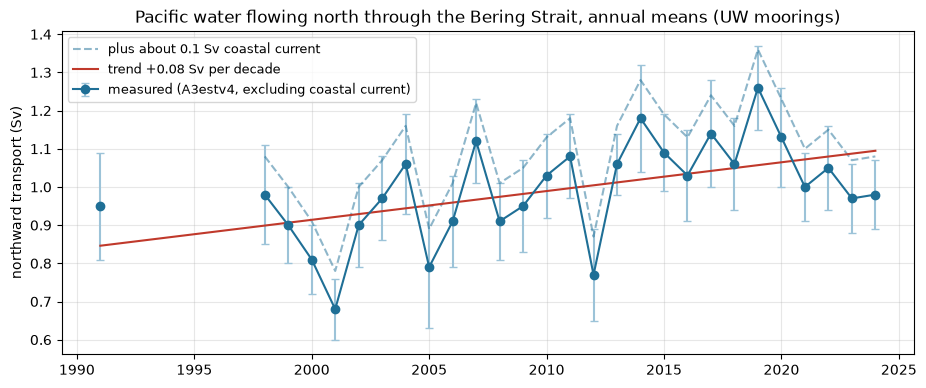

In [5]:
tr = annual["TRANSPORT"]
year_col = tr.columns[0]
best = "A3estv4" if "A3estv4" in tr.columns else tr.columns[-2]
best_err = "A3estv4err" if "A3estv4err" in tr.columns else tr.columns[-1]
ann = pd.DataFrame({"year": tr[year_col].astype(int), "transport_sv": tr[best], "transport_err_sv": tr[best_err]})
ann["transport_with_acc_sv"] = ann["transport_sv"] + ACC_SV

fit = ann[(ann["year"] >= TREND_FROM) & (ann["year"] <= TREND_TO)].dropna(subset=["transport_sv"])
slope, intercept = np.polyfit(fit["year"], fit["transport_sv"], 1)
first = intercept + slope * fit["year"].min()
last = intercept + slope * fit["year"].max()
print("Years with an annual value:", len(fit), "of", TREND_TO - TREND_FROM + 1)
print("Trend:", round(slope, 4), "Sv per year, about", round(slope * 10, 3), "Sv per decade")
print("Trend line from", round(first, 2), "Sv in", fit["year"].min(), "to", round(last, 2), "Sv in", fit["year"].max(), "(", round((last / first - 1) * 100), "% )")
print("Highest year:", int(fit.loc[fit["transport_sv"].idxmax(), "year"]), round(fit["transport_sv"].max(), 2), "Sv; lowest:", int(fit.loc[fit["transport_sv"].idxmin(), "year"]), round(fit["transport_sv"].min(), 2), "Sv")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.errorbar(ann["year"], ann["transport_sv"], yerr=ann["transport_err_sv"], fmt="o-", color="#1f6f96", ecolor="#9cc3d8", capsize=3, label=f"measured ({best}, excluding coastal current)")
ax.plot(ann["year"], ann["transport_with_acc_sv"], "--", color="#1f6f96", alpha=0.5, label=f"plus about {ACC_SV} Sv coastal current")
ax.plot(fit["year"], intercept + slope * fit["year"], color="#c0392b", label=f"trend {slope * 10:+.2f} Sv per decade")
ax.set_ylabel("northward transport (Sv)")
ax.set_title("Pacific water flowing north through the Bering Strait, annual means (UW moorings)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "03_annual_transport.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 5. The other annual means

Every numeric column except the year and error columns, so we can see which moorings each file has.

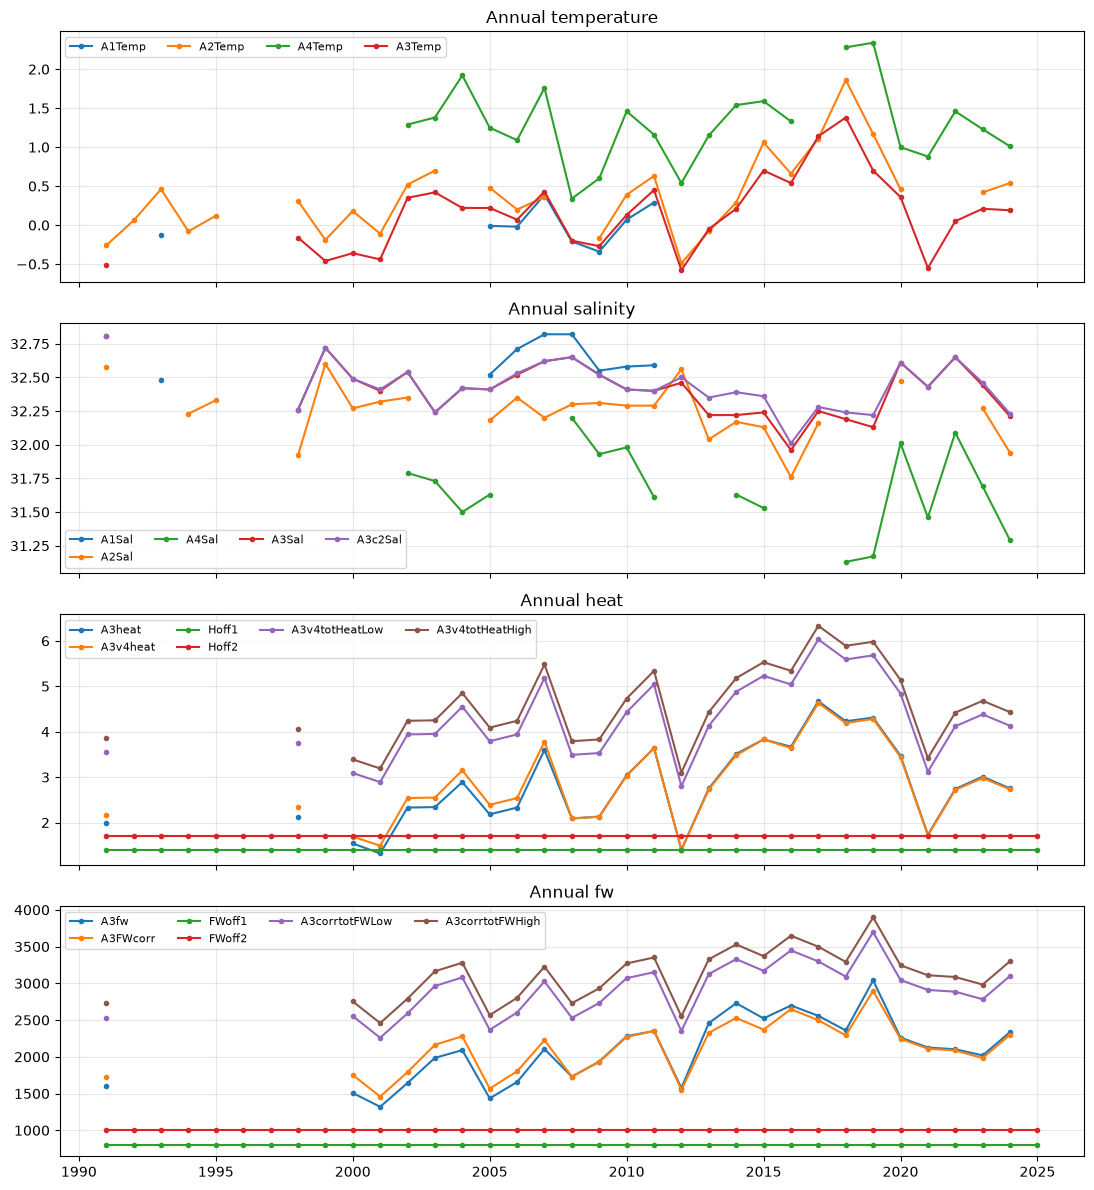

In [6]:
fig, axes = plt.subplots(len(ANNUAL_VARS) - 1, 1, figsize=(11, 3 * (len(ANNUAL_VARS) - 1)), sharex=True)
for ax, v in zip(axes, ANNUAL_VARS[1:]):
    df = annual[v]
    yc = df.columns[0]
    for c in df.columns[1:]:
        if "year" in c.lower() or "err" in c.lower():
            continue
        ax.plot(df[yc], df[c], "o-", markersize=3, label=c)
    ax.set_title(f"Annual {v.lower()}")
    ax.legend(fontsize=8, ncol=4)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_annual_other.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 6. Monthly means at A3: seasons and years

A tidy table with one row per month, then the average year (climatology) and a year by month picture of the transport.

In [7]:
rows = None
for v in MONTHLY_VARS:
    df = monthly[v]
    cols = list(df.columns)
    part = pd.DataFrame({"year": df[cols[1]].astype(int), "month": df[cols[2]].astype(int), v.lower(): df[cols[3]], v.lower() + "_err": df[cols[4]]})
    rows = part if rows is None else rows.merge(part, on=["year", "month"], how="outer")
mon = rows.sort_values(["year", "month"]).reset_index(drop=True)
mon.to_csv(DATA_DIR / "uw_monthly.csv", index=False)
ann.to_csv(DATA_DIR / "uw_annual.csv", index=False)
print("Saved uw_monthly.csv:", len(mon), "rows,", int(mon["transport"].notna().sum()), "months with transport")
print("Saved uw_annual.csv:", len(ann), "rows")

clim = mon.groupby("month")[["transport", "temperature", "salinity"]].mean()
print(clim.round(2))

Saved uw_monthly.csv: 432 rows, 359 months with transport
Saved uw_annual.csv: 35 rows
       transport  temperature  salinity
month                                  
1           0.62        -1.72     32.16
2           0.82        -1.78     32.52
3           0.89        -1.79     32.75
4           0.97        -1.77     32.76
5           1.26        -1.30     32.51
6           1.37         0.31     32.41
7           1.29         1.99     32.47
8           1.12         2.49     32.49
9           0.91         2.70     32.51
10          0.86         2.72     32.39
11          0.75         1.00     32.06
12          0.60        -1.13     31.94


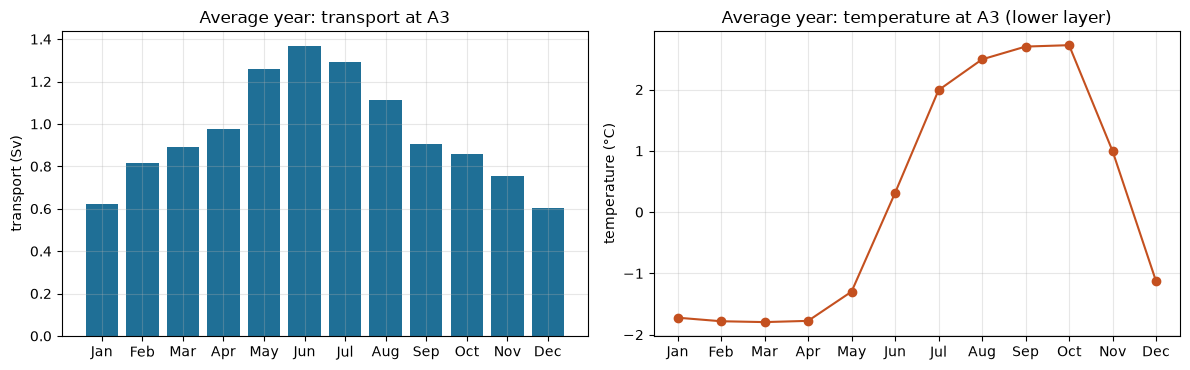

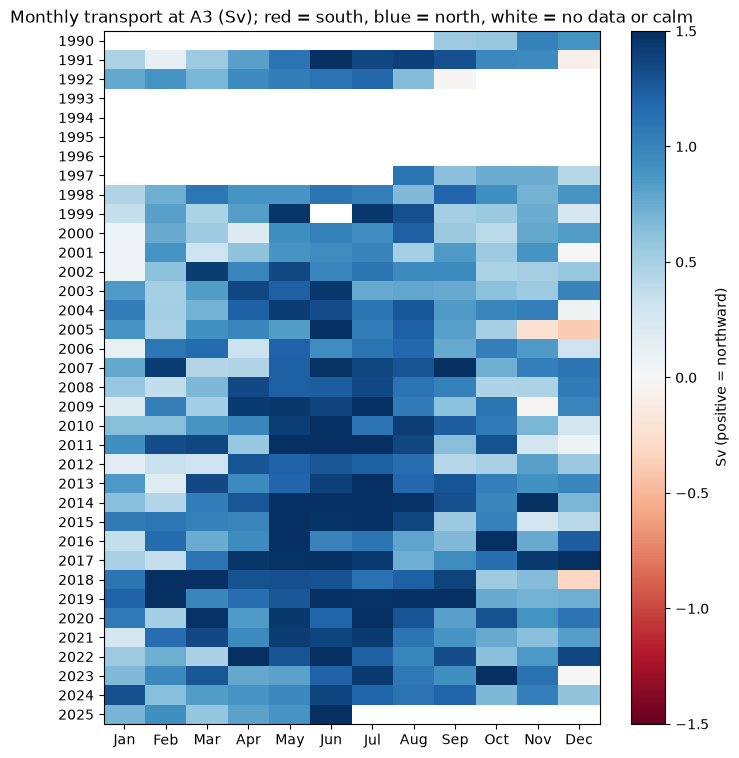

In [8]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(clim.index, clim["transport"], color="#1f6f96")
axes[0].set_xticks(range(1, 13), month_names)
axes[0].set_ylabel("transport (Sv)")
axes[0].set_title("Average year: transport at A3")
axes[1].plot(clim.index, clim["temperature"], "o-", color="#c4501f")
axes[1].set_xticks(range(1, 13), month_names)
axes[1].set_ylabel("temperature (°C)")
axes[1].set_title("Average year: temperature at A3 (lower layer)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_monthly_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

grid = mon.pivot(index="year", columns="month", values="transport")
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(grid.values, aspect="auto", cmap="RdBu", vmin=-1.5, vmax=1.5, origin="upper")
ax.set_xticks(range(12), month_names)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_title("Monthly transport at A3 (Sv); red = south, blue = north, white = no data or calm")
fig.colorbar(im, ax=ax, label="Sv (positive = northward)")
fig.savefig(FIG_DIR / "03_monthly_grid.png", dpi=150, bbox_inches="tight")
plt.show()

___
**END**